# 02. 데이터 전처리 – 라벨 정제 · YOLO 변환 · 조합 단위 분할

EDA(01)에서 찾은 문제를 **사람 손으로 하나씩 고치지 않고, 규칙으로 탐지·수정·기록**한다.
같은 노트북을 다시 돌리면 같은 결과가 나오도록(재현성) 모든 수정은 코드와 로그로 남긴다.

| 단계 | 내용 | 산출물 |
|---|---|---|
| 1 | 흩어진 JSON을 이미지 단위로 병합 | 원본 라벨 테이블 |
| 2 | 고전 영상처리(OpenCV)로 알약 영역 분할 | 알약 후보 박스 |
| 3 | 라벨 박스 vs 알약 영역 대조 → 라벨 감사(audit) | 의심 라벨 목록 |
| 4 | 규칙 기반 수정: 범위 밖 박스 · 엉뚱한 위치 박스 · 누락 박스 | `label_fixes.csv` |
| 5 | 최종 무결성 검사 | – |
| 6 | 조합(combo) 단위 Stratified Group K-Fold | `folds.csv` |
| 7 | YOLO / COCO 형식으로 내보내기 + 왕복 검증 | `datasets/pill/`, `annotations_clean.json` |

## 0. 환경 설정

In [1]:
import json
import os
import platform
import shutil
import subprocess
import sys
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
N_FOLDS = 5
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def find_data_root() -> Path:
    """train_annotations 폴더를 가진 데이터 루트를 찾는다."""
    if os.environ.get("PILL_DATA_DIR"):
        return Path(os.environ["PILL_DATA_DIR"])
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for depth in ("*", "*/*", "*/*/*"):
            hits = list(kaggle_input.glob(f"{depth}/train_annotations"))
            if hits:
                return hits[0].parent
    # 로컬: 레포 폴더 옆(형제 폴더)의 sprint_ai_project1_data 또는 상위 폴더
    for cand in (Path.cwd(), *Path.cwd().parents):
        for root in (cand, cand / "sprint_ai_project1_data"):
            if (root / "train_annotations").exists():
                return root
    raise FileNotFoundError("데이터 폴더를 찾지 못했다. PILL_DATA_DIR 환경 변수를 지정하자.")


DATA_ROOT = find_data_root()
TRAIN_IMG_DIR = DATA_ROOT / "train_images"
ANN_DIR = DATA_ROOT / "train_annotations"

IS_KAGGLE = Path("/kaggle/working").exists()
REPO_DIR = Path.cwd().parent  # notebooks/ 의 상위 = 레포 루트
OUT_DIR = Path("/kaggle/working") if IS_KAGGLE else REPO_DIR / "reports"
FIG_DIR = OUT_DIR / "figures"
DATASET_DIR = (Path("/kaggle/working") if IS_KAGGLE else REPO_DIR) / "datasets" / "pill"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT  :", DATA_ROOT)
print("OUT_DIR    :", OUT_DIR)
print("DATASET_DIR:", DATASET_DIR)

DATA_ROOT  : C:\Users\user\Desktop\ai_15기\###프로젝트\sprint_ai_project1_data
OUT_DIR    : C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\reports
DATASET_DIR: C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\datasets\pill


In [2]:
def setup_korean_font() -> bool:
    """한글 폰트를 설정한다. 실패하면 False (영문 약품명으로 대체)."""
    if platform.system() == "Windows":
        plt.rcParams["font.family"] = "Malgun Gothic"
        return True
    try:
        import koreanize_matplotlib  # noqa: F401
        return True
    except ImportError:
        pass
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"], check=True)
        import koreanize_matplotlib  # noqa: F401
        return True
    except Exception as e:
        print("한글 폰트 설치 실패 → 영문 약품명 사용:", e)
        return False


KOREAN_OK = setup_korean_font()
plt.rcParams["axes.unicode_minus"] = False
NAME_COL = "dl_name" if KOREAN_OK else "dl_name_en"


def save_fig(fig, name: str):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def load_rgb(path: Path) -> np.ndarray:
    """PIL로 읽는다. cv2.imread는 Windows에서 한글 경로를 읽지 못한다."""
    return np.asarray(Image.open(path).convert("RGB"))

## 1. 라벨 병합
JSON 하나에 알약 하나씩 들어 있으므로 이미지 이름 기준으로 모은다. 박스는 `[x1, y1, x2, y2]` 좌표로도 함께 들고 다닌다.

In [3]:
rows = []
for p in sorted(ANN_DIR.rglob("*.json")):
    with open(p, encoding="utf-8") as f:
        d = json.load(f)
    img = d["images"][0]
    for a in d["annotations"]:
        x, y, w, h = a["bbox"]
        rows.append({
            "file_name": img["file_name"], "category_id": a["category_id"],
            "dl_name": img["dl_name"], "dl_name_en": img["dl_name_en"],
            "x": float(x), "y": float(y), "w": float(w), "h": float(h),
            "img_w": img["width"], "img_h": img["height"], "camera_la": img["camera_la"],
            "source": "original",
        })

raw = pd.DataFrame(rows)
raw["combo"] = raw["file_name"].str.split("_").str[0]
train_files = sorted(p.name for p in TRAIN_IMG_DIR.glob("*.png"))
names = raw.drop_duplicates("category_id").set_index("category_id")[["dl_name", "dl_name_en"]]

assert raw["img_w"].nunique() == 1 and raw["img_h"].nunique() == 1, "이미지 크기가 섞여 있다"
IMG_W, IMG_H = int(raw["img_w"].iloc[0]), int(raw["img_h"].iloc[0])
print(f"이미지 {raw.file_name.nunique()}장 / 박스 {len(raw)}개 / 클래스 {raw.category_id.nunique()}개 / 크기 {IMG_W}×{IMG_H}")


def expected_codes(file_name: str) -> list:
    """파일명 앞부분(조합 코드)에 적힌 약 코드 = 사진에 놓인 알약 목록."""
    return sorted(int(c) for c in file_name.split("_")[0].split("-")[1:])

이미지 232장 / 박스 763개 / 클래스 56개 / 크기 976×1280


## 2. 알약 영역 분할 (고전 영상처리)
라벨이 맞는지 검증하려면 **라벨과 독립적인 기준**이 필요하다. 배경이 단색에 가깝다는 EDA 결과를 이용해 알약을 분리한다.

1. 1/4로 축소 (속도, 잡음 감소)
2. Lab 색공간으로 변환. 사람 눈의 색 차이와 비슷한 거리를 준다
3. 큰 median blur로 **배경만 남긴 이미지**를 추정. 알약(약 60px)보다 큰 커널이라 알약이 지워진다
4. 원본과 배경의 색 거리 → Otsu 이진화 → 모폴로지로 잡음 제거
5. 연결 요소를 박스로 만든다. 가장자리에 닿는 영역(비네팅)과 작은 영역은 제외

한계: 반투명 연질캡슐(OMACOR)이나 배경과 색이 비슷한 흰 알약은 일부만 잡힌다.
그래서 이 결과를 **정답으로 쓰지 않고, 라벨을 의심할 근거와 보완 후보로만** 쓴다.

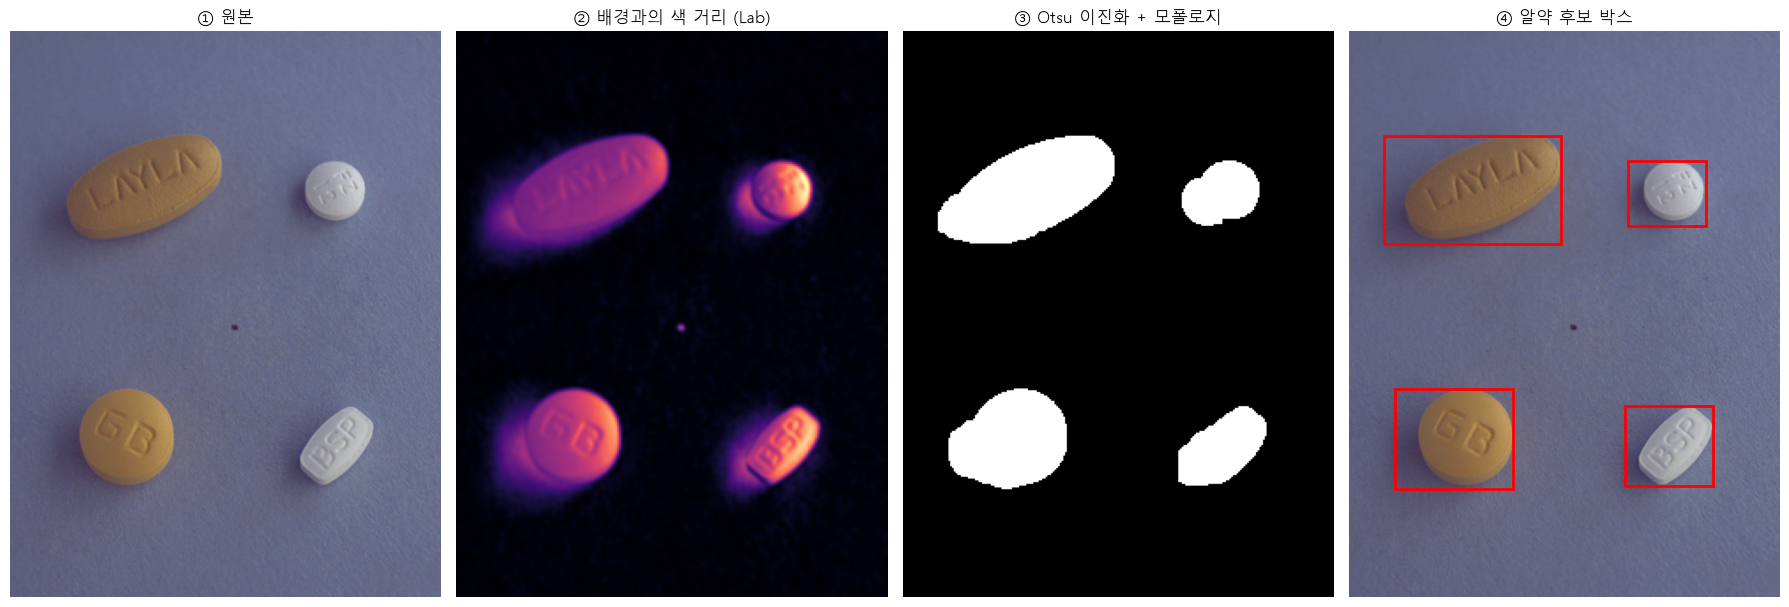

In [4]:
SEG_SCALE = 4


def segment_pills(img_rgb: np.ndarray, scale: int = SEG_SCALE, blur: int = 101, min_area: int = 400):
    """배경 차분으로 알약 후보 박스(원본 좌표 [x1,y1,x2,y2])와 축소 마스크를 반환한다."""
    small = cv2.resize(img_rgb, None, fx=1 / scale, fy=1 / scale, interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB)
    bg = np.dstack([cv2.medianBlur(lab[..., i], blur) for i in range(3)])
    dist = np.linalg.norm(lab.astype(np.float32) - bg.astype(np.float32), axis=2)
    dist = cv2.GaussianBlur(dist, (5, 5), 0)
    _, mask = cv2.threshold(np.clip(dist, 0, 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    H, W = mask.shape
    boxes = []
    for x, y, w, h, area in stats[1:]:
        if area < min_area or x == 0 or y == 0 or x + w >= W or y + h >= H:
            continue
        boxes.append([x * scale, y * scale, (x + w) * scale, (y + h) * scale])
    return np.array(boxes, dtype=float).reshape(-1, 4), mask, dist


# 한 장으로 과정 시각화
demo = train_files[0]
demo_img = load_rgb(TRAIN_IMG_DIR / demo)
demo_boxes, demo_mask, demo_dist = segment_pills(demo_img)
fig, axes = plt.subplots(1, 4, figsize=(18, 6))
axes[0].imshow(demo_img); axes[0].set_title("① 원본")
axes[1].imshow(demo_dist, cmap="magma"); axes[1].set_title("② 배경과의 색 거리 (Lab)")
axes[2].imshow(demo_mask, cmap="gray"); axes[2].set_title("③ Otsu 이진화 + 모폴로지")
axes[3].imshow(demo_img); axes[3].set_title("④ 알약 후보 박스")
for x1, y1, x2, y2 in demo_boxes:
    axes[3].add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=2))
for ax in axes:
    ax.axis("off")
plt.tight_layout()
save_fig(fig, "14_segmentation_steps")
plt.show()

In [5]:
segments, masks = {}, {}
for f in train_files:
    segments[f], masks[f], _ = segment_pills(load_rgb(TRAIN_IMG_DIR / f))
print("분할 완료:", len(segments), "장 / 이미지당 후보 수:", dict(Counter(len(v) for v in segments.values())))

분할 완료: 232 장 / 이미지당 후보 수: {4: 73, 5: 1, 3: 156, 2: 2}


## 3. 라벨 감사 (Label Audit)
각 라벨 박스에 대해 다음을 계산한다.
- `best_iou`: 가장 잘 겹치는 알약 후보와의 IoU
- `fg_ratio`: 박스 안에서 알약(전경) 픽셀이 차지하는 비율. **0에 가까우면 빈 배경에 그려진 박스**다

그리고 어떤 라벨과도 겹치지 않는 알약 후보(= **라벨이 없는 알약**)를 찾는다.

       best_iou  fg_ratio
count   763.000   763.000
mean      0.792     0.623
std       0.103     0.106
min       0.000     0.000
25%       0.777     0.580
50%       0.808     0.639
75%       0.835     0.684
max       0.931     0.844


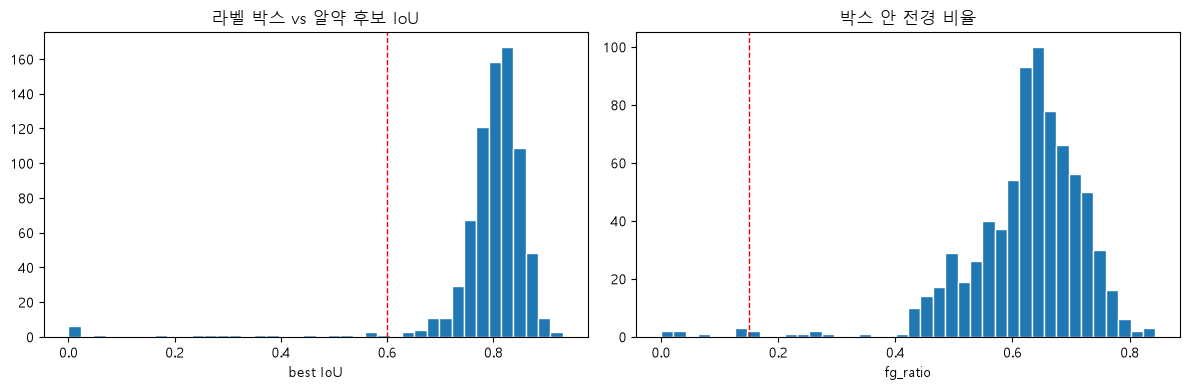

In [6]:
def to_xyxy(df: pd.DataFrame) -> np.ndarray:
    return np.c_[df["x"], df["y"], df["x"] + df["w"], df["y"] + df["h"]]


def iou_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """a(N,4), b(M,4) xyxy → (N,M) IoU."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def containment(seg: np.ndarray, boxes: np.ndarray) -> np.ndarray:
    """seg(M,4)가 boxes(N,4) 안에 들어간 비율 (M,N). 반투명 캡슐의 조각 영역을 '이미 라벨된 것'으로 보기 위함."""
    if len(seg) == 0 or len(boxes) == 0:
        return np.zeros((len(seg), len(boxes)))
    ix1 = np.maximum(seg[:, None, 0], boxes[None, :, 0]); iy1 = np.maximum(seg[:, None, 1], boxes[None, :, 1])
    ix2 = np.minimum(seg[:, None, 2], boxes[None, :, 2]); iy2 = np.minimum(seg[:, None, 3], boxes[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    return inter / ((seg[:, 2] - seg[:, 0]) * (seg[:, 3] - seg[:, 1]))[:, None]


def fg_ratio(mask: np.ndarray, box: np.ndarray, scale: int = SEG_SCALE) -> float:
    x1, y1, x2, y2 = np.clip((box / scale).round().astype(int), 0, None)
    region = mask[y1:y2, x1:x2]
    return float((region > 0).mean()) if region.size else 0.0


def unmatched_segments(f: str, df: pd.DataFrame) -> np.ndarray:
    """어떤 라벨과도 겹치지 않고, 라벨 안에 포함되지도 않는 알약 후보."""
    seg = segments[f]
    boxes = to_xyxy(df[df["file_name"] == f])
    if len(seg) == 0:
        return seg
    keep = (iou_matrix(seg, boxes).max(axis=1, initial=0) < 0.1) & (containment(seg, boxes).max(axis=1, initial=0) < 0.5)
    return seg[keep]


def audit(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    xyxy = to_xyxy(out)
    out["best_iou"] = [iou_matrix(xyxy[i:i + 1], segments[f]).max(initial=0) for i, f in enumerate(out["file_name"])]
    out["fg_ratio"] = [fg_ratio(masks[f], xyxy[i]) for i, f in enumerate(out["file_name"])]
    out["out_of_bounds"] = (xyxy[:, 0] < 0) | (xyxy[:, 1] < 0) | (xyxy[:, 2] > out["img_w"]) | (xyxy[:, 3] > out["img_h"])
    return out


aud = audit(raw)
print(aud[["best_iou", "fg_ratio"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(aud["best_iou"], bins=40, edgecolor="white"); axes[0].set(title="라벨 박스 vs 알약 후보 IoU", xlabel="best IoU")
axes[1].hist(aud["fg_ratio"], bins=40, edgecolor="white"); axes[1].set(title="박스 안 전경 비율", xlabel="fg_ratio")
for ax in axes:
    ax.axvline(0.15 if ax is axes[1] else 0.6, c="red", ls="--", lw=1)
plt.tight_layout()
save_fig(fig, "15_label_audit_hist")
plt.show()

IoU가 낮은 박스가 꽤 있지만, 눈으로 확인하면 대부분은 **분할이 실패한 경우**(반투명 캡슐, 흰 알약)이고 라벨은 맞다.
그래서 IoU 하나로 판단하지 않고, 아래처럼 **오류 유형별로 엄격한 규칙**을 둔다.

| 오류 유형 | 탐지 규칙 | 수정 규칙 |
|---|---|---|
| A. 범위 밖 박스 | 좌표가 이미지 밖 | 좌표에서 숫자 하나를 뺀 후보들 중 **라벨 없는 알약과 IoU가 가장 큰** 값 (자릿수 입력 오류 가정) |
| B. 엉뚱한 위치 박스 | 박스 안 전경 비율 < 0.15 **그리고** 누락 라벨이 없는 이미지 **그리고** 원래 박스와 겹치지 않고 크기가 비슷한(0.7~1.4배) 라벨 없는 알약이 정확히 1개 | 그 알약 위치로 박스를 옮긴다 |
| C. 누락 박스 | 파일명상 약 코드 중 라벨 없는 코드가 정확히 1개 **그리고** 라벨 없는 알약이 정확히 1개 | 그 알약에 해당 코드로 박스를 추가 |

대응이 하나로 정해지지 않는 경우(후보 0개 또는 2개 이상)는 자동 수정하지 않고 보고만 한다.

### 박스 보정 (calibration)
분할 박스는 1/4 해상도에서 나와 라벨러가 그린 박스와 테두리 기준이 조금 다르다.
잘 맞는 쌍(IoU > 0.75)에서 테두리 차이의 중앙값을 구해, 새로 만드는 박스를 **라벨러 기준에 맞춘다**.

In [7]:
pairs = []
for f, g in aud[~aud["out_of_bounds"]].groupby("file_name"):
    seg = segments[f]
    if len(seg) == 0:
        continue
    lab = to_xyxy(g)
    m = iou_matrix(lab, seg)
    for i, j in zip(range(len(lab)), m.argmax(axis=1)):
        if m[i, j] > 0.75:
            pairs.append(lab[i] - seg[j])
CALIB = np.median(np.array(pairs), axis=0)
print(f"보정용 쌍 {len(pairs)}개 / 테두리 보정값 [dx1, dy1, dx2, dy2] = {CALIB.round(1)}")


def calibrated(seg_box: np.ndarray, img_w: int, img_h: int) -> np.ndarray:
    b = seg_box + CALIB
    return np.clip(b, 0, [img_w, img_h, img_w, img_h])

보정용 쌍 677개 / 테두리 보정값 [dx1, dy1, dx2, dy2] = [-9. -9. 11.  9.]


### 규칙 기반 수정

In [8]:
clean = raw.copy()
fixes = []


def log_fix(kind, f, cid, before, after, note):
    fixes.append({"type": kind, "file_name": f, "category_id": cid, "name": names.loc[cid, "dl_name"],
                  "before": None if before is None else [round(float(v), 1) for v in before],
                  "after": [round(float(v), 1) for v in after], "note": note})


# A. 범위 밖 박스: 자릿수 하나가 잘못 들어간 경우를 가정해 복원
for idx in aud.index[aud["out_of_bounds"]]:
    r = clean.loc[idx]
    f = r.file_name
    others = clean[(clean["file_name"] == f) & (clean.index != idx)]
    free = unmatched_segments(f, others)
    best = None
    for col, limit, size in (("x", r.img_w, r.w), ("y", r.img_h, r.h)):
        v = str(int(r[col]))
        if r[col] >= 0 and r[col] + size <= limit:
            continue
        for k in range(len(v)):
            cand = int(v[:k] + v[k + 1:]) if len(v) > 1 else 0
            if cand + size > limit:
                continue
            box = np.array([[cand, r.y, cand + r.w, r.y + r.h]]) if col == "x" else np.array([[r.x, cand, r.x + r.w, cand + r.h]])
            score = iou_matrix(box, free).max(initial=0)
            if best is None or score > best[0]:
                best = (score, col, cand)
    if best and best[0] > 0.5:
        before = [r.x, r.y, r.w, r.h]
        clean.loc[idx, best[1]] = best[2]
        log_fix("A_out_of_bounds", f, r.category_id, before, clean.loc[idx, ["x", "y", "w", "h"]].tolist(),
                f"{best[1]}={int(r[best[1]])} → {best[2]} (라벨 없는 알약과 IoU {best[0]:.2f})")
    else:
        print("⚠ 자동 복원 실패 → 수동 확인 필요:", f)

# B. 엉뚱한 위치 박스: 빈 배경에 그려진 박스를 라벨 없는 알약으로 옮긴다
aud_b = audit(clean)
for idx in aud_b.index[(aud_b["fg_ratio"] < 0.15) & ~aud_b["out_of_bounds"]]:
    r = clean.loc[idx]
    if set(expected_codes(r.file_name)) - set(clean.loc[clean["file_name"] == r.file_name, "category_id"]):
        continue  # 누락 라벨이 있는 이미지는 C 규칙이 처리한다 (라벨 없는 알약을 잘못 가져가지 않도록)
    free = unmatched_segments(r.file_name, clean[clean.index != idx])
    # 같은 알약을 엉뚱한 곳에 그렸다면: (1) 원래 박스와 전혀 겹치지 않고 (2) 크기가 비슷해야 한다.
    # 반투명 캡슐처럼 분할이 일부만 잡힌 경우(작은 조각, 원래 박스와 겹침)를 여기서 걸러낸다.
    own = np.array([[r.x, r.y, r.x + r.w, r.y + r.h]])
    if len(free):
        ratio_w = (free[:, 2] - free[:, 0] + CALIB[2] - CALIB[0]) / r.w
        ratio_h = (free[:, 3] - free[:, 1] + CALIB[3] - CALIB[1]) / r.h
        no_overlap = iou_matrix(free, own)[:, 0] == 0
        similar_size = (ratio_w > 0.7) & (ratio_w < 1.4) & (ratio_h > 0.7) & (ratio_h < 1.4)
        free = free[no_overlap & similar_size]
    if len(free) == 1:
        nb = calibrated(free[0], r.img_w, r.img_h)
        before = [r.x, r.y, r.w, r.h]
        clean.loc[idx, ["x", "y", "w", "h"]] = [nb[0], nb[1], nb[2] - nb[0], nb[3] - nb[1]]
        clean.loc[idx, "source"] = "relocated"
        log_fix("B_misplaced", r.file_name, r.category_id, before, clean.loc[idx, ["x", "y", "w", "h"]].tolist(),
                f"박스 안 전경 비율 {aud_b.loc[idx, 'fg_ratio']:.2f} → 라벨 없는 알약 위치로 이동")
    else:
        print(f"ℹ 전경 비율 낮음, 라벨 없는 알약 {len(free)}개 → 수정 안 함 (분할 실패로 판단): {r.file_name} / {r.dl_name}")

# C. 누락 박스: 파일명에 있는데 라벨이 없는 약 코드 → 라벨 없는 알약에 추가
new_rows = []
for f, g in clean.groupby("file_name"):
    miss = sorted(set(expected_codes(f)) - set(g["category_id"]))
    if not miss:
        continue
    free = unmatched_segments(f, g)
    if len(miss) == 1 and len(free) == 1:
        r0 = g.iloc[0]
        nb = calibrated(free[0], r0.img_w, r0.img_h)
        cid = miss[0]
        new_rows.append({**r0.to_dict(), "category_id": cid, "dl_name": names.loc[cid, "dl_name"],
                         "dl_name_en": names.loc[cid, "dl_name_en"], "x": nb[0], "y": nb[1],
                         "w": nb[2] - nb[0], "h": nb[3] - nb[1], "source": "added"})
        log_fix("C_missing", f, cid, None, [nb[0], nb[1], nb[2] - nb[0], nb[3] - nb[1]], "파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가")
    else:
        print(f"⚠ 누락 {miss}, 라벨 없는 알약 {len(free)}개 → 자동 보완 불가: {f}")

clean = pd.concat([clean, pd.DataFrame(new_rows)], ignore_index=True)
fix_log = pd.DataFrame(fixes)
fix_log.to_csv(OUT_DIR / "label_fixes.csv", index=False, encoding="utf-8-sig")
print(f"\n수정 {len(fix_log)}건:", dict(Counter(fix_log["type"])))
fix_log

ℹ 전경 비율 낮음, 라벨 없는 알약 0개 → 수정 안 함 (분할 실패로 판단): K-003351-003832-016688_0_2_0_2_70_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
ℹ 전경 비율 낮음, 라벨 없는 알약 0개 → 수정 안 함 (분할 실패로 판단): K-003351-016688-018147_0_2_0_2_70_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
ℹ 전경 비율 낮음, 라벨 없는 알약 0개 → 수정 안 함 (분할 실패로 판단): K-003351-016688-018147_0_2_0_2_75_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
ℹ 전경 비율 낮음, 라벨 없는 알약 0개 → 수정 안 함 (분할 실패로 판단): K-003351-016688-031863_0_2_0_2_90_000_200.png / 오마코연질캡슐(오메가-3-산에틸에스테르90)
ℹ 전경 비율 낮음, 라벨 없는 알약 0개 → 수정 안 함 (분할 실패로 판단): K-003483-020877-031885-036637_0_2_0_2_70_000_200.png / 자누메트엑스알서방정 100/1000mg
ℹ 전경 비율 낮음, 라벨 없는 알약 0개 → 수정 안 함 (분할 실패로 판단): K-003483-020877-031885-036637_0_2_0_2_90_000_200.png / 자누메트엑스알서방정 100/1000mg

수정 10건: {'A_out_of_bounds': 1, 'B_misplaced': 1, 'C_missing': 8}


,type,file_name,category_id,name,before,after,note
0,A_out_of_bounds,K-003351-016262-018357_0_2_0_2_75_000_200.png,18357,종근당글리아티린연질캡슐(콜린알포세레이트),"[6567.0, 625.0, 311.0, 315.0]","[567.0, 625.0, 311.0, 315.0]",x=6567 → 567 (라벨 없는 알약과 IoU 0.87)
1,B_misplaced,K-003351-020014-020238_0_2_0_2_90_000_200.png,3351,일양하이트린정 2mg,"[185.0, 249.0, 188.0, 183.0]","[383.0, 243.0, 192.0, 206.0]",박스 안 전경 비율 0.00 → 라벨 없는 알약 위치로 이동
2,C_missing,K-003351-013900-021325_0_2_0_2_70_000_200.png,3351,일양하이트린정 2mg,None,"[387.0, 835.0, 188.0, 194.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
3,C_missing,K-003351-013900-036637_0_2_0_2_70_000_200.png,3351,일양하이트린정 2mg,None,"[431.0, 867.0, 188.0, 190.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
4,C_missing,K-003351-020014-022074_0_2_0_2_90_000_200.png,20014,마도파정,None,"[59.0, 715.0, 328.0, 326.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
5,C_missing,K-003351-021325-032310_0_2_0_2_90_000_200.png,32310,글리아타민연질캡슐,None,"[583.0, 819.0, 368.0, 242.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
6,C_missing,K-003351-032310-038162_0_2_0_2_70_000_200.png,3351,일양하이트린정 2mg,None,"[383.0, 859.0, 184.0, 190.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
7,C_missing,K-003351-033880-038162_0_2_0_2_75_000_200.png,33880,글리틴정(콜린알포세레이트),None,"[67.0, 595.0, 296.0, 426.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
8,C_missing,K-003351-035206-041768_0_2_0_2_70_000_200.png,3351,일양하이트린정 2mg,None,"[455.0, 875.0, 188.0, 190.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가
9,C_missing,K-003544-004543-012247-016548_0_2_0_2_90_000_2...,4543,에어탈정(아세클로페낙),None,"[631.0, 195.0, 248.0, 202.0]",파일명에 있으나 라벨 없음 → 라벨 없는 알약에 추가


### 수정 전 / 후 비교 (눈으로 검수)
자동 수정은 반드시 사람이 확인한다. 위: 원본 라벨, 아래: 정제 라벨. **노란 박스가 수정·추가된 박스**다.

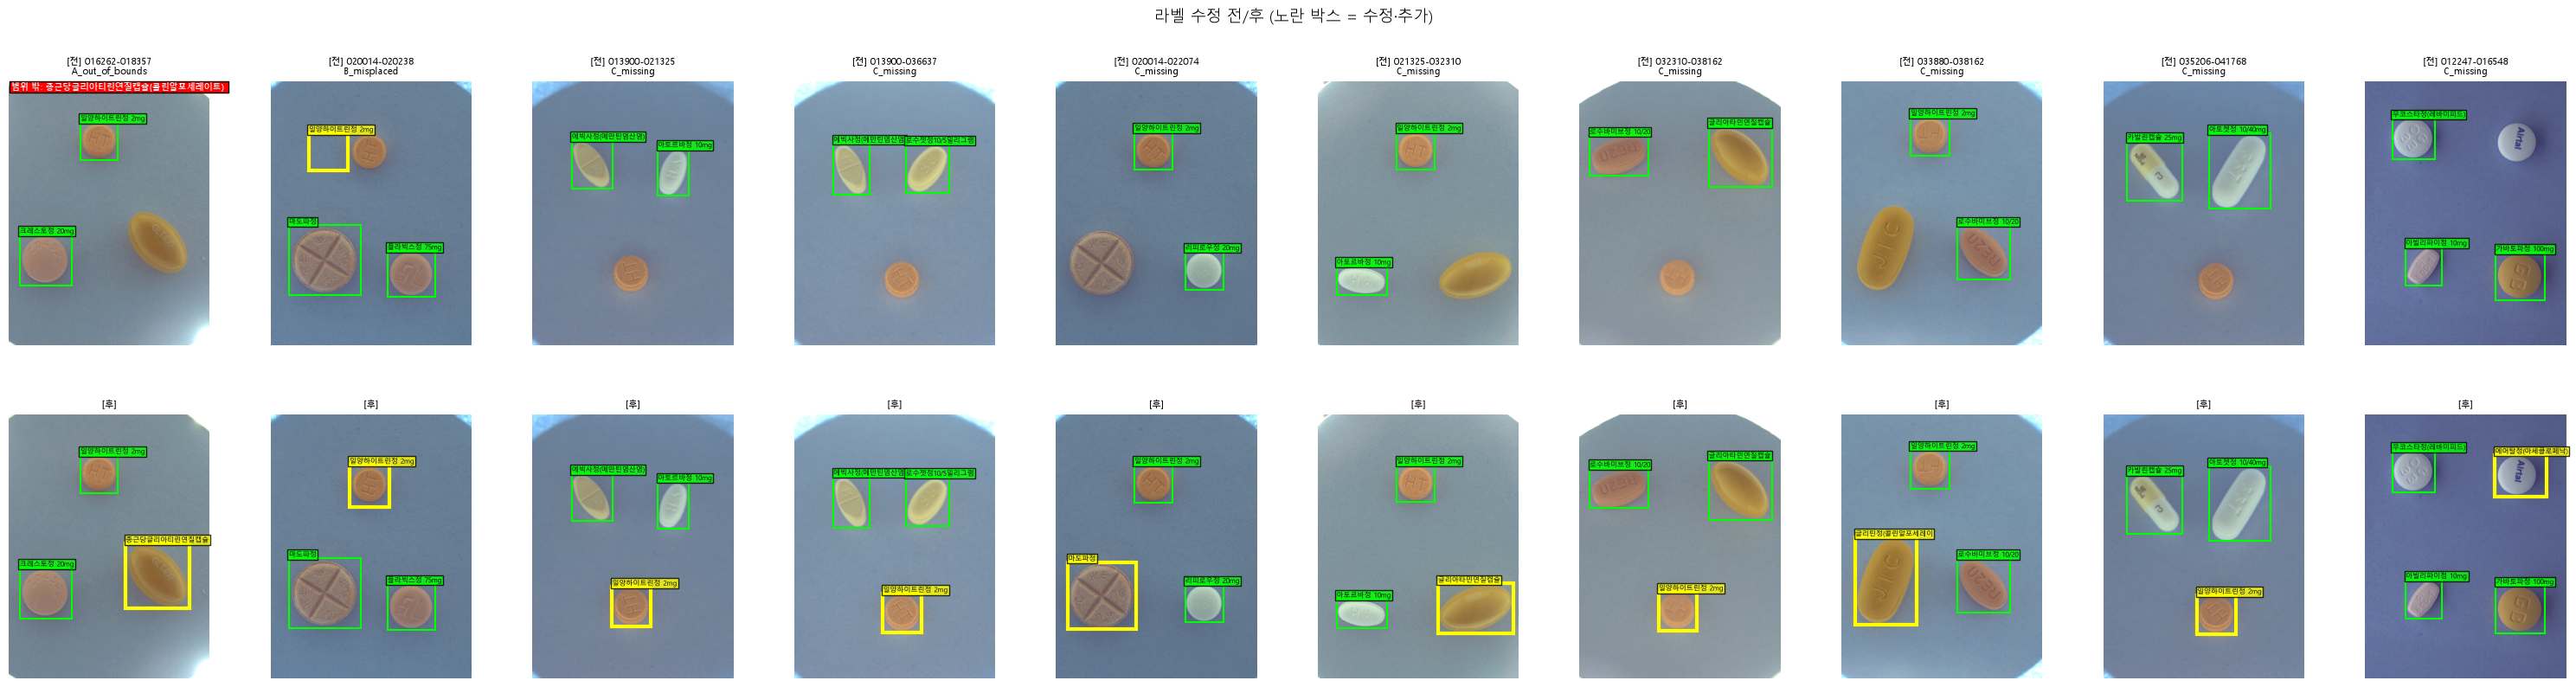

In [9]:
def draw(ax, f, df, title):
    ax.imshow(Image.open(TRAIN_IMG_DIR / f))
    W, H = Image.open(TRAIN_IMG_DIR / f).size
    for _, r in df[df["file_name"] == f].iterrows():
        x1, y1 = max(r.x, 0), max(r.y, 0)
        x2, y2 = min(r.x + r.w, W), min(r.y + r.h, H)
        if x2 <= x1 or y2 <= y1:
            ax.text(10, 40, f"범위 밖: {r[NAME_COL]}", color="white", fontsize=7, bbox=dict(fc="red", pad=1))
            continue
        changed = r.get("source", "original") != "original" or (f, r.category_id) in fixed_keys
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=3 if changed else 1.5,
                                       ec="yellow" if changed else "lime"))
        ax.text(x1, max(y1 - 6, 0), str(r[NAME_COL])[:12], fontsize=6, color="black",
                bbox=dict(fc="yellow" if changed else "lime", alpha=0.8, pad=1))
    ax.set_title(title, fontsize=8)
    ax.axis("off")


fixed_keys = set(zip(fix_log["file_name"], fix_log["category_id"]))
fix_files = list(dict.fromkeys(fix_log["file_name"]))
fig, axes = plt.subplots(2, len(fix_files), figsize=(3 * len(fix_files), 8.5))
for j, f in enumerate(fix_files):
    t = fix_log[fix_log["file_name"] == f]["type"].iloc[0]
    draw(axes[0, j], f, raw, f"[전] {f.split('_')[0][-13:]}\n{t}")
    draw(axes[1, j], f, clean, "[후]")
fig.suptitle("라벨 수정 전/후 (노란 박스 = 수정·추가)", fontsize=13)
plt.tight_layout()
save_fig(fig, "16_label_fixes_before_after")
plt.show()

## 5. 최종 무결성 검사
모든 조건을 `assert`로 확인한다. 하나라도 어긋나면 여기서 멈춘다.

In [10]:
final_aud = audit(clean)
per_img = clean.groupby("file_name")["category_id"].apply(sorted)

assert set(per_img.index) == set(train_files), "라벨 없는 이미지가 있다"
assert not final_aud["out_of_bounds"].any(), "범위 밖 박스가 남아 있다"
assert (clean["w"] > 0).all() and (clean["h"] > 0).all(), "크기 0 박스"
assert not clean.duplicated(["file_name", "category_id"]).any(), "같은 이미지에 같은 클래스 중복"
mismatch = [f for f, codes in per_img.items() if codes != expected_codes(f)]
assert not mismatch, f"파일명과 라벨 불일치: {mismatch}"

print("✅ 모든 검사 통과")
print(f"이미지 {clean.file_name.nunique()}장 / 박스 {len(raw)} → {len(clean)}개")
print("박스 출처:", dict(Counter(clean["source"])))
print("이미지당 박스 수:", dict(Counter(clean.groupby("file_name").size())))

✅ 모든 검사 통과
이미지 232장 / 박스 763 → 771개
박스 출처: {'original': 762, 'relocated': 1, 'added': 8}
이미지당 박스 수: {4: 75, 3: 157}


## 6. 클래스 번호 매핑
YOLO는 클래스 번호가 0부터 연속이어야 한다. 원래 `category_id`(약 코드) 순으로 0~55를 붙인다.
**제출 시에는 이 표로 다시 원래 코드로 되돌린다.**

In [11]:
class_map = (
    clean.groupby("category_id")
    .agg(dl_name=("dl_name", "first"), dl_name_en=("dl_name_en", "first"),
         n_boxes=("file_name", "size"), n_images=("file_name", "nunique"), n_combos=("combo", "nunique"))
    .reset_index().sort_values("category_id").reset_index(drop=True)
)
class_map.insert(0, "yolo_id", range(len(class_map)))
class_map.to_csv(OUT_DIR / "class_map.csv", index=False, encoding="utf-8-sig")
cat2yolo = dict(zip(class_map["category_id"], class_map["yolo_id"]))
clean["yolo_id"] = clean["category_id"].map(cat2yolo)
print(f"클래스 {len(class_map)}개 → yolo_id 0~{len(class_map) - 1}")
class_map.head()

클래스 56개 → yolo_id 0~55


,yolo_id,category_id,dl_name,dl_name_en,n_boxes,n_images,n_combos
0,0,1900,보령부스파정 5mg,Buspar Tab. 5mg Boryung,15,15,5
1,1,2483,뮤테란캡슐 100mg,Muteran Cap. 100mg,9,9,3
2,2,3351,일양하이트린정 2mg,Hytrin Tab. 2mg Ilyang,157,157,89
3,3,3483,기넥신에프정(은행엽엑스)(수출용),Ginexin-F Tab.,45,45,15
4,4,3544,무코스타정(레바미피드)(비매품),Mucosta Tab.,6,6,2


## 7. 조합 단위 Stratified Group K-Fold
- **Group = 조합(combo)**: 같은 조합의 각도만 다른 사진이 train/val에 나뉘면 누수다. 조합 전체를 한 fold에 넣는다.
- **Stratify = 이미지의 가장 희귀한 클래스**: 희귀 클래스가 한 fold에 몰리지 않게 분산한다.
- 1개 조합에만 있는 클래스 17개는 구조적으로 train과 val 양쪽에 있을 수 없다. 그 클래스가 val에 있는 fold에서는 **처음 보는 약**이 된다.
  이건 결함이 아니라 *새로운 조합의 사진에 얼마나 일반화되는가* 를 정직하게 재는 것이다.
- 최종 제출 모델은 232장 **전체**로 학습한다. K-Fold는 실험 비교와 하이퍼파라미터 결정에 쓴다.

In [12]:
img_tbl = clean.groupby("file_name").agg(combo=("combo", "first"), camera_la=("camera_la", "first"),
                                         classes=("category_id", lambda s: sorted(s))).reset_index()
freq = clean["category_id"].value_counts()
img_tbl["rarest"] = img_tbl["classes"].apply(lambda cs: min(cs, key=lambda c: freq[c]))

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
img_tbl["fold"] = -1
for k, (_, val_idx) in enumerate(sgkf.split(img_tbl, y=img_tbl["rarest"], groups=img_tbl["combo"])):
    img_tbl.loc[val_idx, "fold"] = k

# 누수 검사: 어떤 조합도 두 fold에 걸치면 안 된다
assert img_tbl.groupby("combo")["fold"].nunique().max() == 1, "조합이 여러 fold에 걸쳐 있다"

summary = []
for k in range(N_FOLDS):
    va = img_tbl[img_tbl["fold"] == k]
    tr = img_tbl[img_tbl["fold"] != k]
    va_cls = set(c for cs in va["classes"] for c in cs)
    tr_cls = set(c for cs in tr["classes"] for c in cs)
    summary.append({"fold": k, "val_images": len(va), "val_combos": va["combo"].nunique(),
                    "val_boxes": int(va["classes"].str.len().sum()), "val_classes": len(va_cls),
                    "val_classes_unseen_in_train": len(va_cls - tr_cls)})
fold_summary = pd.DataFrame(summary)
img_tbl[["file_name", "combo", "camera_la", "fold"]].to_csv(OUT_DIR / "folds.csv", index=False, encoding="utf-8-sig")
print("✅ 누수 검사 통과 (조합이 fold 사이에 겹치지 않음)")
fold_summary

✅ 누수 검사 통과 (조합이 fold 사이에 겹치지 않음)


C:\Users\user\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:1036: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


,fold,val_images,val_combos,val_boxes,val_classes,val_classes_unseen_in_train
0,0,47,23,156,33,5
1,1,46,22,153,33,3
2,2,46,23,150,29,1
3,3,46,22,153,32,7
4,4,47,24,159,33,3


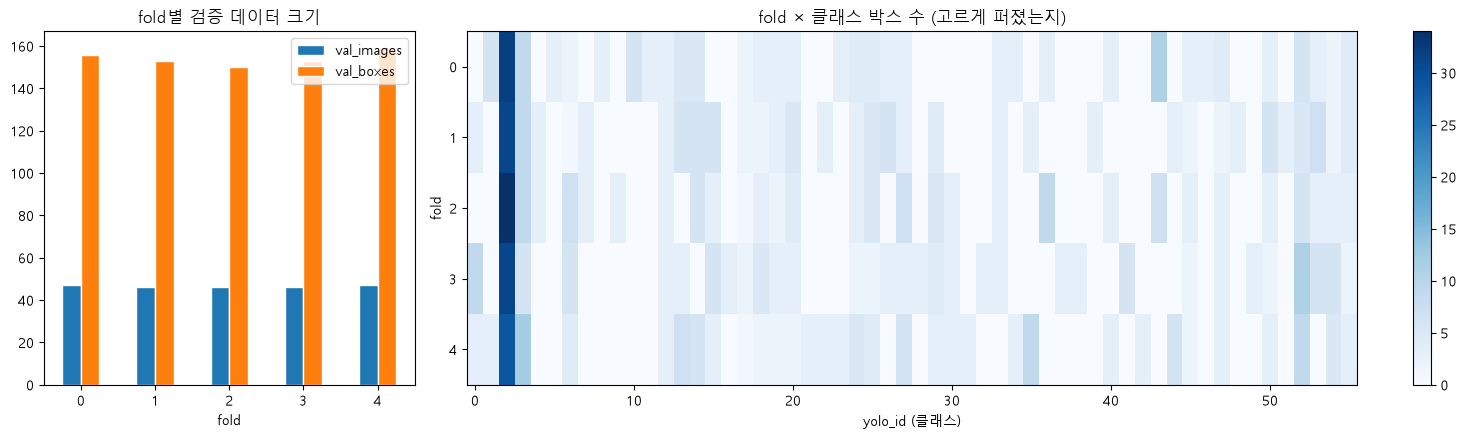

In [13]:
box_fold = clean.merge(img_tbl[["file_name", "fold"]], on="file_name")
ct = pd.crosstab(box_fold["yolo_id"], box_fold["fold"])
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 3]})
fold_summary.set_index("fold")[["val_images", "val_boxes"]].plot(kind="bar", ax=axes[0], rot=0, edgecolor="white")
axes[0].set_title("fold별 검증 데이터 크기")
im = axes[1].imshow(ct.T.values, aspect="auto", cmap="Blues")
axes[1].set(xlabel="yolo_id (클래스)", ylabel="fold", title="fold × 클래스 박스 수 (고르게 퍼졌는지)")
axes[1].set_yticks(range(N_FOLDS))
fig.colorbar(im, ax=axes[1])
plt.tight_layout()
save_fig(fig, "17_fold_distribution")
plt.show()

## 8. 내보내기
### YOLO 형식
```
datasets/pill/
├── images/*.png          (원본 링크 또는 복사)
├── labels/*.txt          (class cx cy w h, 0~1 정규화)
├── fold{k}_train.txt / fold{k}_val.txt
├── data_fold{k}.yaml     (K-Fold 실험용)
└── data_full.yaml        (최종 학습용: 전체 학습, val은 fold0 – 모니터링 전용)
```
Ultralytics는 이미지 경로의 `/images/`를 `/labels/`로 바꿔 라벨을 찾기 때문에 이 구조를 따른다.
클래스 이름은 학습 그래프에서 글자가 깨지지 않게 영문명을 쓴다.

In [14]:
img_out, lbl_out = DATASET_DIR / "images", DATASET_DIR / "labels"
# 폴더를 지우고 바로 다시 만들면 Windows에서 권한 오류가 나므로, 폴더는 두고 내용만 새로 쓴다
img_out.mkdir(parents=True, exist_ok=True)
lbl_out.mkdir(parents=True, exist_ok=True)
for stale in [*lbl_out.glob("*.txt"), *DATASET_DIR.glob("*.txt"), *DATASET_DIR.glob("*.yaml")]:
    stale.unlink()

link_mode = "symlink"
for f in train_files:
    src, dst = TRAIN_IMG_DIR / f, img_out / f
    if dst.is_symlink() or dst.exists():
        dst.unlink()
    try:
        os.symlink(src, dst)
    except OSError:  # Windows 일반 권한에서는 심볼릭 링크가 막혀 있다 → 복사
        link_mode = "copy"
        shutil.copy2(src, dst)

for f, g in clean.groupby("file_name"):
    lines = []
    for r in g.sort_values("yolo_id").itertuples():
        cx, cy = (r.x + r.w / 2) / r.img_w, (r.y + r.h / 2) / r.img_h
        lines.append(f"{r.yolo_id} {cx:.6f} {cy:.6f} {r.w / r.img_w:.6f} {r.h / r.img_h:.6f}")
    (lbl_out / f.replace(".png", ".txt")).write_text("\n".join(lines) + "\n", encoding="utf-8")

yolo_names = {int(r.yolo_id): r.dl_name_en.strip() for r in class_map.itertuples()}


def write_split(name: str, files) -> str:
    (DATASET_DIR / name).write_text("\n".join(f"./images/{f}" for f in files) + "\n", encoding="utf-8")
    return name


def write_yaml(name: str, train_txt: str, val_txt: str):
    cfg = {"path": str(DATASET_DIR), "train": train_txt, "val": val_txt, "nc": len(yolo_names), "names": yolo_names}
    with open(DATASET_DIR / name, "w", encoding="utf-8") as fp:
        yaml.safe_dump(cfg, fp, allow_unicode=True, sort_keys=False)


for k in range(N_FOLDS):
    tr = write_split(f"fold{k}_train.txt", img_tbl.loc[img_tbl["fold"] != k, "file_name"])
    va = write_split(f"fold{k}_val.txt", img_tbl.loc[img_tbl["fold"] == k, "file_name"])
    write_yaml(f"data_fold{k}.yaml", tr, va)
write_yaml("data_full.yaml", write_split("all_train.txt", img_tbl["file_name"]), "fold0_val.txt")

print(f"이미지 {len(list(img_out.iterdir()))}장 ({link_mode}) / 라벨 {len(list(lbl_out.iterdir()))}개")
print(sorted(p.name for p in DATASET_DIR.iterdir() if p.is_file()))
print((DATASET_DIR / "data_fold0.yaml").read_text(encoding="utf-8")[:300], "...")

이미지 232장 (copy) / 라벨 232개
['all_train.txt', 'data_fold0.yaml', 'data_fold1.yaml', 'data_fold2.yaml', 'data_fold3.yaml', 'data_fold4.yaml', 'data_full.yaml', 'fold0_train.txt', 'fold0_val.txt', 'fold1_train.txt', 'fold1_val.txt', 'fold2_train.txt', 'fold2_val.txt', 'fold3_train.txt', 'fold3_val.txt', 'fold4_train.txt', 'fold4_val.txt']
path: C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\datasets\pill
train: fold0_train.txt
val: fold0_val.txt
nc: 56
names:
  0: Buspar Tab. 5mg Boryung
  1: Muteran Cap. 100mg
  2: Hytrin Tab. 2mg Ilyang
  3: Ginexin-F Tab.
  4: Mucosta Tab.
  5: Aldrin Tab.
  6: Neuromed Tab. 800mg
  7: Airtal ...


### COCO 형식 (정제본)
다른 프레임워크(torchvision Faster R-CNN 등)와 pycocotools 평가에 쓰도록 **원래 약 코드**를 유지한 COCO 파일도 만든다.

In [15]:
coco = {"images": [], "annotations": [], "categories": []}
img_id = {f: i + 1 for i, f in enumerate(train_files)}
for f in train_files:
    coco["images"].append({"id": img_id[f], "file_name": f, "width": IMG_W, "height": IMG_H})
for i, r in enumerate(clean.sort_values(["file_name", "category_id"]).itertuples(), start=1):
    coco["annotations"].append({"id": i, "image_id": img_id[r.file_name], "category_id": int(r.category_id),
                                "bbox": [round(r.x, 1), round(r.y, 1), round(r.w, 1), round(r.h, 1)],
                                "area": round(r.w * r.h, 1), "iscrowd": 0})
for r in class_map.itertuples():
    coco["categories"].append({"id": int(r.category_id), "name": r.dl_name, "supercategory": "pill"})
with open(OUT_DIR / "annotations_clean.json", "w", encoding="utf-8") as fp:
    json.dump(coco, fp, ensure_ascii=False)
print(f"COCO: images {len(coco['images'])} / annotations {len(coco['annotations'])} / categories {len(coco['categories'])}")

COCO: images 232 / annotations 771 / categories 56


### 왕복 검증
저장한 YOLO 라벨을 **다시 읽어 픽셀 좌표로 되돌리고** 정제 라벨과 비교한다. 변환 실수(가로·세로 뒤바뀜, 정규화 오류)를 잡는다.

In [16]:
yolo2cat = {v: k for k, v in cat2yolo.items()}
back = []
for txt in lbl_out.glob("*.txt"):
    for line in txt.read_text(encoding="utf-8").strip().splitlines():
        c, cx, cy, w, h = line.split()
        c, cx, cy, w, h = int(c), float(cx), float(cy), float(w), float(h)
        assert 0 <= cx <= 1 and 0 <= cy <= 1 and 0 < w <= 1 and 0 < h <= 1
        back.append({"file_name": txt.stem + ".png", "category_id": yolo2cat[c],
                     "x_b": (cx - w / 2) * IMG_W, "y_b": (cy - h / 2) * IMG_H, "w_b": w * IMG_W, "h_b": h * IMG_H})
back = pd.DataFrame(back).merge(clean, on=["file_name", "category_id"], how="outer", indicator=True)
assert (back["_merge"] == "both").all(), "라벨 개수가 맞지 않는다"
err = np.abs(back[["x_b", "y_b", "w_b", "h_b"]].values - back[["x", "y", "w", "h"]].values).max()
assert err < 0.01, err
print(f"✅ 왕복 검증 통과: 박스 {len(back)}개, 최대 좌표 오차 {err:.5f}px")

✅ 왕복 검증 통과: 박스 771개, 최대 좌표 오차 0.00096px


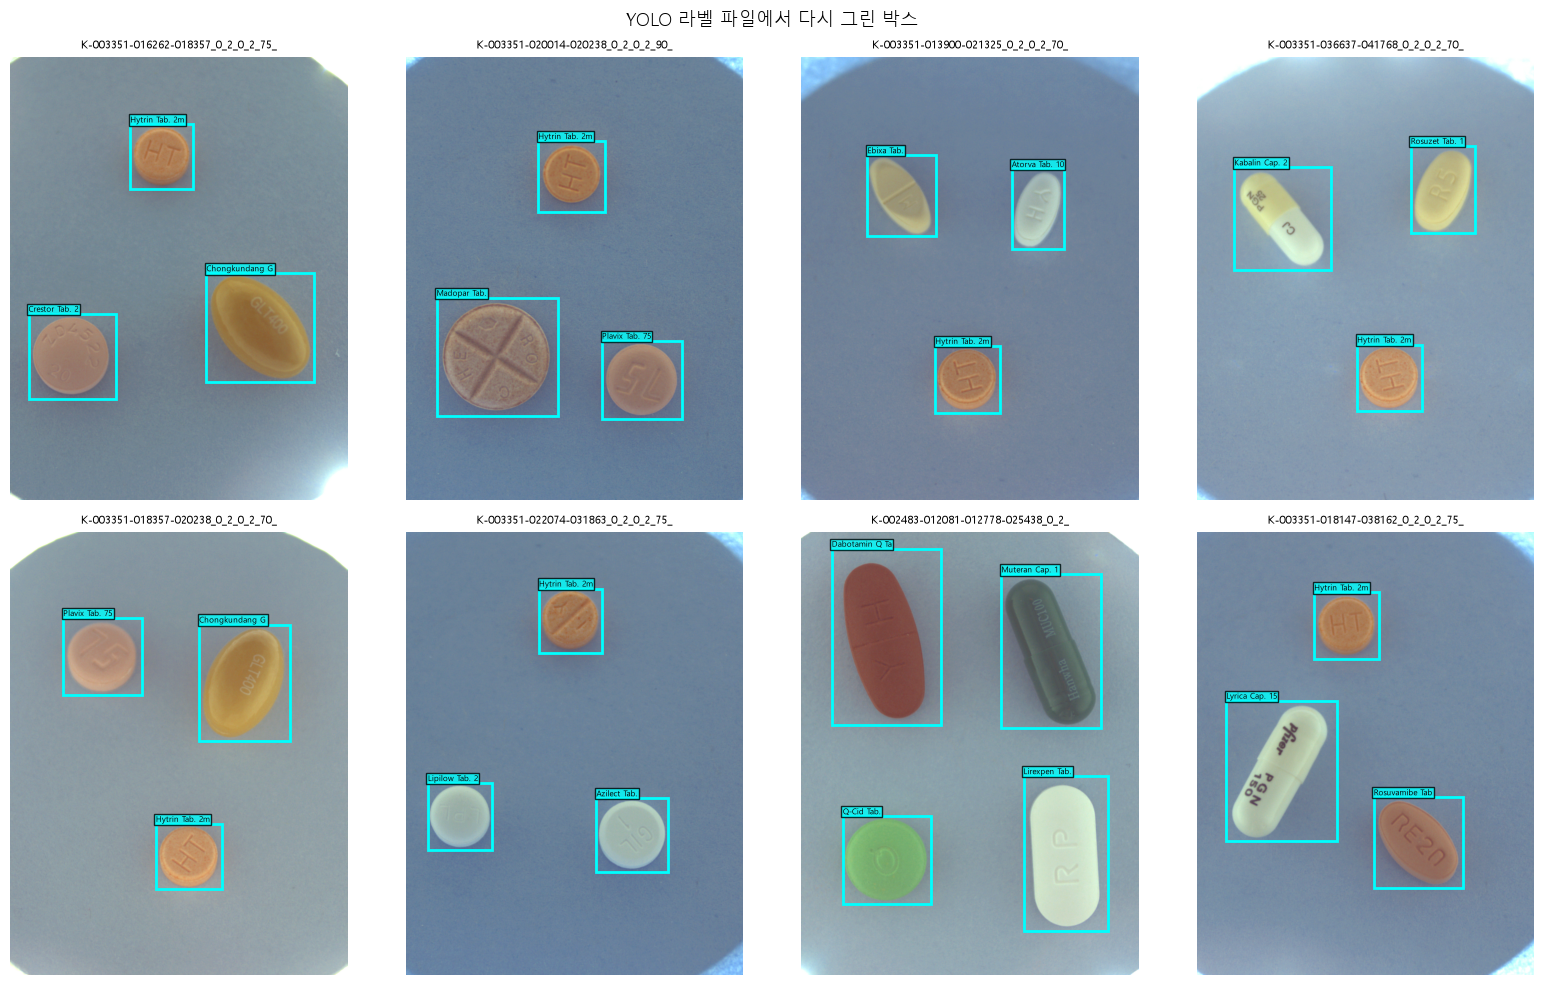

In [17]:
rng = np.random.default_rng(SEED)
show = list(fix_files[:3]) + list(rng.choice(train_files, 5, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(16, 10))
for ax, f in zip(axes.flat, show):
    ax.imshow(Image.open(img_out / f))
    for line in (lbl_out / f.replace(".png", ".txt")).read_text(encoding="utf-8").strip().splitlines():
        c, cx, cy, w, h = map(float, line.split())
        ax.add_patch(patches.Rectangle(((cx - w / 2) * IMG_W, (cy - h / 2) * IMG_H), w * IMG_W, h * IMG_H,
                                       fill=False, ec="cyan", lw=2))
        ax.text((cx - w / 2) * IMG_W, (cy - h / 2) * IMG_H - 6, yolo_names[int(c)][:14], fontsize=6,
                bbox=dict(fc="cyan", alpha=0.8, pad=1))
    ax.set_title(f[:34], fontsize=8)
    ax.axis("off")
fig.suptitle("YOLO 라벨 파일에서 다시 그린 박스", fontsize=13)
plt.tight_layout()
save_fig(fig, "18_yolo_export_check")
plt.show()

## 9. 요약

| 항목 | 결과 |
|---|---|
| 라벨 정제 | 범위 밖 박스 복원, 엉뚱한 위치 박스 이동, 누락 박스 추가. 모든 수정은 `label_fixes.csv`에 기록 |
| 무결성 | 모든 이미지에서 파일명의 약 목록 = 라벨 약 목록, 범위 밖·중복 박스 0 |
| 검증 분할 | 조합 단위 Stratified Group 5-Fold, 조합 누수 0 |
| 산출물 | YOLO 데이터셋 + fold별 yaml, COCO 정제본, `class_map.csv`, `folds.csv` |

**다음 단계 (03_train)**: `data_fold0.yaml`로 YOLO 베이스라인 → 첫 Kaggle 제출 → 개선 실험